# Wind exposure (Sx) for each NISAR pair

Same Sx method as `7_wind_exposure.ipynb`, but the prevailing wind direction is recomputed for the time interval of every pair in `coherence_80m.zarr`. Still the small test box at 10 m, not the full basin.

In [1]:
import sys, os, glob
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import rioxarray as rxr
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource, TwoSlopeNorm

project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

%load_ext autoreload
%autoreload 2
from scripts.stations import read_mesowest_wind, wind_in_interval, prevailing_direction, plot_wind_rose
from scripts.wind_exposure import compute_sx

data_dir = project_root + '/data/'
fig_dir = Path(project_root) / 'outputs' / 'figures' / 'wind_exposure_by_pair'
fig_dir.mkdir(parents=True, exist_ok=True)

Read the pair start/end times (local standard time, UTC-7) and the raw station winds. As before, the direction comes from CASCP + SOSC2 pooled, ignoring calm (<1 m/s) readings.

In [2]:
coh = xr.open_zarr(data_dir + 'nisar/zarrs/track019_frame021/coherence_80m.zarr', consolidated=False)
pairs = pd.DataFrame({'pair': coh.pair.values, 'start': pd.to_datetime(coh.start.values), 'end': pd.to_datetime(coh.end.values)})

wind = read_mesowest_wind(sorted(glob.glob(data_dir + 'stations/mesowest/*.csv')))
names = {'CACNM': 'Cinnamon Mtn', 'CASCP': 'Irwin Guides Ridge', 'SOSC2': 'Schofield Pass'}
DIR_STATIONS = ['CASCP', 'SOSC2']
print('station record starts', pd.to_datetime(wind.time).min() - pd.Timedelta(hours=7), '(local)')
pairs

station record starts 2025-12-01 05:00:00 (local)


,pair,start,end
0,20251123_20251205,2025-11-23 05:11:16,2025-12-05 05:11:16
1,20251205_20251217,2025-12-05 05:11:16,2025-12-17 05:11:17
2,20251217_20251229,2025-12-17 05:11:17,2025-12-29 05:11:18
3,20251229_20260110,2025-12-29 05:11:18,2026-01-10 05:11:18
4,20260110_20260122,2026-01-10 05:11:18,2026-01-22 05:11:19
5,20260122_20260203,2026-01-22 05:11:19,2026-02-03 05:11:19
6,20260203_20260215,2026-02-03 05:11:19,2026-02-15 05:11:20
7,20260215_20260227,2026-02-15 05:11:20,2026-02-27 05:11:20
8,20260227_20260311,2026-02-27 05:11:20,2026-03-11 05:11:21
9,20260311_20260323,2026-03-11 05:11:21,2026-03-23 05:11:21


Compute the prevailing direction for every interval. The first pair starts a week before the station records do, so its direction rests on fewer days.

In [3]:
rows = []
for p in pairs.itertuples():
    k = wind_in_interval(wind[wind.station.isin(DIR_STATIONS)], p.start, p.end)
    d, R = prevailing_direction(k.speed, k.direction)
    first = (pd.to_datetime(wind.time).min() - pd.Timedelta(hours=7))
    days = (p.end - max(p.start, first)).days
    rows.append(dict(pair=p.pair, azimuth=round(d), R=round(R, 2), n_obs=int((k.speed >= 1).sum()), days_with_data=days))
dirs = pd.DataFrame(rows).set_index('pair')
dirs

,azimuth,R,n_obs,days_with_data
pair,,,,
20251123_20251205,273,0.83,84,4
20251205_20251217,268,0.84,247,12
20251217_20251229,234,0.92,382,12
20251229_20260110,246,0.74,255,12
20260110_20260122,282,0.50,368,12
20260122_20260203,267,0.82,345,12
20260203_20260215,245,0.80,267,12
20260215_20260227,243,0.93,351,12
20260227_20260311,246,0.90,318,12


Download of the DEM is already done, so load the 10 m DEM from the first notebook and compute Sx for all three dmax values for each pair. Each run takes a few seconds.

In [4]:
BOX = {'x': (315960, 325000), 'y': (4307500, 4320500)}
DMAXS = (100, 300, 500)
dem = rxr.open_rasterio(project_root + '/data/dem/dem_10m_testbox.tif', masked=True).squeeze(drop=True)

layers = []
for pair, row in dirs.iterrows():
    s = compute_sx(dem, row.azimuth, DMAXS)
    s = s.sel(x=slice(*BOX['x']), y=slice(BOX['y'][1], BOX['y'][0]))
    layers.append(s.drop_vars('spatial_ref').expand_dims(pair=[pair]))
sx_pairs = xr.concat(layers, dim='pair').rio.write_crs(dem.rio.crs)
sx_pairs['wind_from_azimuth'] = ('pair', dirs.azimuth.values.astype('float32'))
sx_pairs['start'] = ('pair', pairs.start.values)
sx_pairs['end'] = ('pair', pairs.end.values)
sx_pairs

<xarray.Dataset> Size: 197MB
Dimensions:            (pair: 14, y: 1300, x: 904)
Coordinates:
  * pair               (pair) object 112B '20251123_20251205' ... '20260428_2...
  * y                  (y) float64 10kB 4.32e+06 4.32e+06 ... 4.308e+06
  * x                  (x) float64 7kB 3.16e+05 3.16e+05 ... 3.25e+05 3.25e+05
    spatial_ref        int64 8B 0
Data variables:
    sx_100             (pair, y, x) float32 66MB 4.128 3.417 ... 15.56 14.16
    sx_300             (pair, y, x) float32 66MB 6.968 6.514 ... 21.65 21.04
    sx_500             (pair, y, x) float32 66MB 7.072 6.674 ... 25.35 24.99
    wind_from_azimuth  (pair) float32 56B 273.0 268.0 234.0 ... 237.0 254.0
    start              (pair) datetime64[ns] 112B 2025-11-23T05:11:16 ... 202...
    end                (pair) datetime64[ns] 112B 2025-12-05T05:11:16 ... 202...

Make one compass-rose figure per pair showing the three stations and the pooled ridge stations that set the direction (red line). Roses are in `outputs/figures/wind_exposure_by_pair/`.

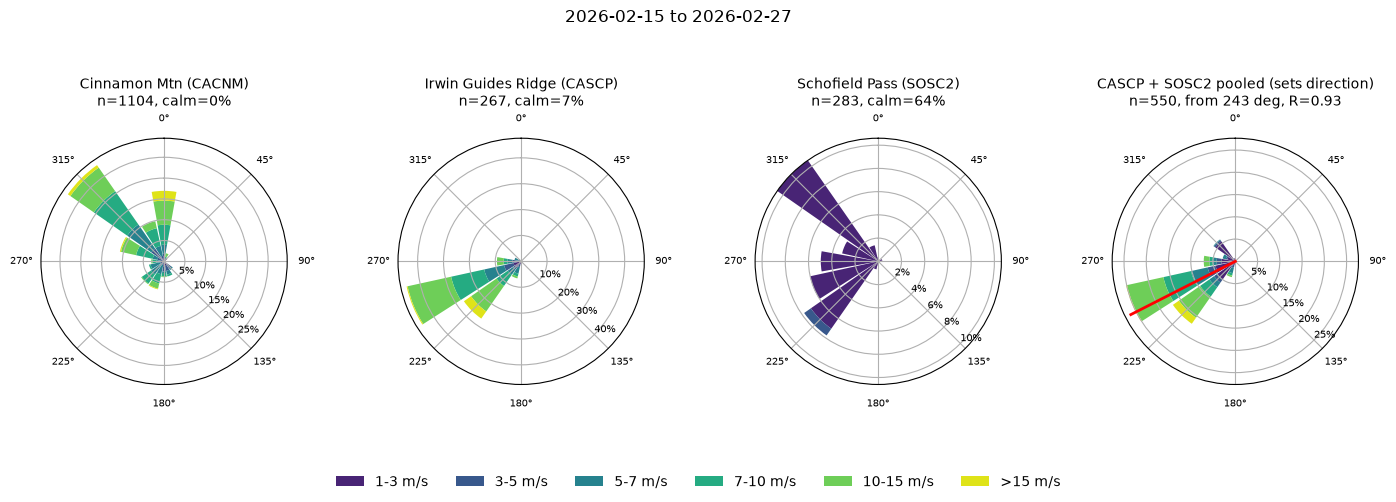

In [5]:
def rose_figure(pair):
    p = pairs.set_index('pair').loc[pair]
    w = wind_in_interval(wind, p.start, p.end)
    fig, axs = plt.subplots(1, 4, figsize=(17, 4.8), subplot_kw={'projection': 'polar'}, gridspec_kw={'wspace': 0.45})
    for ax, stid in zip(axs, ['CACNM', 'CASCP', 'SOSC2']):
        g = w[w.station == stid]
        h = plot_wind_rose(ax, g.speed, g.direction, f'{names[stid]} ({stid})\nn={len(g)}, calm={np.mean(g.speed < 1):.0%}')
    g = w[w.station.isin(DIR_STATIONS)]
    plot_wind_rose(axs[3], g.speed, g.direction, f'CASCP + SOSC2 pooled (sets direction)\nn={len(g)}, from {dirs.azimuth[pair]} deg, R={dirs.R[pair]}')
    axs[3].plot([np.deg2rad(dirs.azimuth[pair])] * 2, [0, axs[3].get_rmax()], color='red', lw=2)
    fig.suptitle(f'{p.start:%Y-%m-%d} to {p.end:%Y-%m-%d}', y=1.02)
    fig.legend(h, [x.get_label() for x in h], loc='lower center', ncol=6, frameon=False)
    fig.savefig(fig_dir / f'roses_{pair}.png', dpi=130, bbox_inches='tight')
    return fig

for pair in pairs.pair:
    plt.close(rose_figure(pair))
rose_figure(pairs.pair[7]);  # example: one pair shown here, all are saved to disk

Make one Sx figure per pair with the same color scale for every pair, so differences between intervals are comparable.

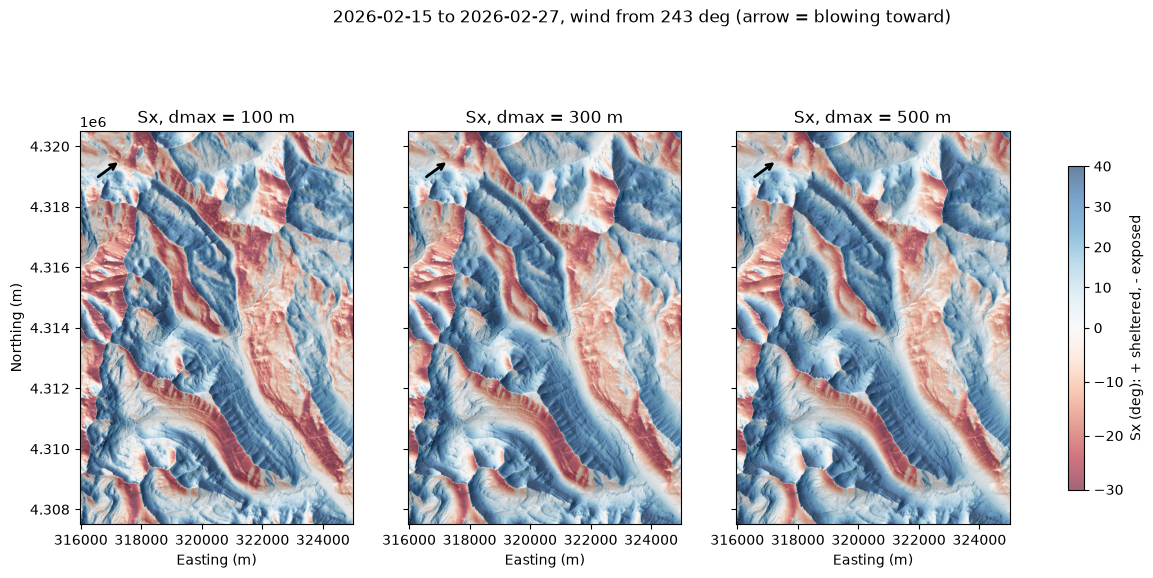

In [6]:
z = dem.sel(x=sx_pairs.x, y=sx_pairs.y).values
hill = LightSource(azdeg=315, altdeg=40).hillshade(z, vert_exag=2, dx=10, dy=10)
ext = [sx_pairs.x.min() - 5, sx_pairs.x.max() + 5, sx_pairs.y.min() - 5, sx_pairs.y.max() + 5]

def sx_figure(pair):
    az = dirs.azimuth[pair]
    p = pairs.set_index('pair').loc[pair]
    fig, axs = plt.subplots(1, 3, figsize=(15, 7), sharey=True)
    for ax, d in zip(axs, DMAXS):
        ax.imshow(hill, cmap='gray', extent=ext)
        im = ax.imshow(sx_pairs[f'sx_{d}'].sel(pair=pair).values, cmap='RdBu', norm=TwoSlopeNorm(0, -30, 40), alpha=0.6, extent=ext)
        ax.set_title(f'Sx, dmax = {d} m')
        ax.set_xlabel('Easting (m)')
        tail = np.array([0.06, 0.88])
        head = tail + 0.1 * np.array([-np.sin(np.deg2rad(az)), -np.cos(np.deg2rad(az))])
        ax.annotate('', xy=head, xytext=tail, xycoords='axes fraction', arrowprops=dict(arrowstyle='->', lw=2))
    axs[0].set_ylabel('Northing (m)')
    fig.colorbar(im, ax=axs, shrink=0.6, label='Sx (deg): + sheltered, - exposed')
    fig.suptitle(f'{p.start:%Y-%m-%d} to {p.end:%Y-%m-%d}, wind from {az} deg (arrow = blowing toward)', y=0.95)
    fig.savefig(fig_dir / f'sx_{pair}.png', dpi=130, bbox_inches='tight')
    return fig

for pair in pairs.pair:
    plt.close(sx_figure(pair))
sx_figure(pairs.pair[7]);  # example: one pair shown here, all are saved to disk

Summarize how the direction and the mean Sx change across the season. Sx changes little where the direction is stable, so the direction series is the main thing to check.

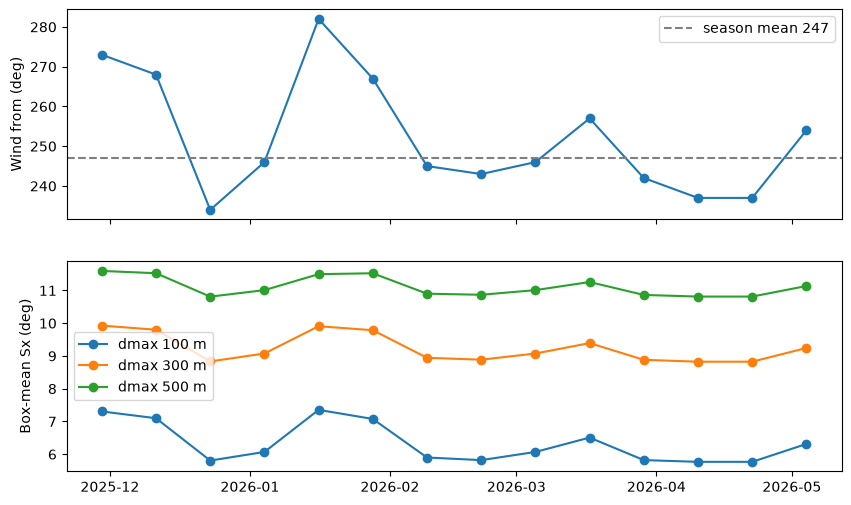

In [7]:
fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
mid = pairs.start + (pairs.end - pairs.start) / 2
axs[0].plot(mid, dirs.azimuth, 'o-'); axs[0].set_ylabel('Wind from (deg)')
axs[0].axhline(247, color='gray', ls='--', label='season mean 247'); axs[0].legend()
for d in DMAXS:
    axs[1].plot(mid, sx_pairs[f'sx_{d}'].mean(['x', 'y']), 'o-', label=f'dmax {d} m')
axs[1].set_ylabel('Box-mean Sx (deg)'); axs[1].legend()
fig.savefig(fig_dir / 'direction_and_mean_sx_by_pair.png', dpi=150, bbox_inches='tight')
plt.show()

Save the per-pair layers as an Xarray Zarr and as one GeoTIFF per dmax with one band per pair (band descriptions are the pair names).

In [8]:
out_dir = Path(project_root) / 'outputs'
sx_pairs.to_zarr(out_dir / 'wind_exposure_10m_by_pair.zarr', mode='w')

(out_dir / 'wind_exposure_10m_by_pair').mkdir(exist_ok=True)
for d in DMAXS:
    da = sx_pairs[f'sx_{d}'].rename({'pair': 'band'})
    da = da.assign_coords(band=np.arange(1, da.sizes['band'] + 1))
    da.rio.to_raster(out_dir / 'wind_exposure_10m_by_pair' / f'sx_{d}_by_pair.tif')
    # rasterio keeps band order, which matches the pair order in the Zarr / dirs table

/Users/JULIALOBER/miniforge3/envs/coherence/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
